# Intensity Distributions
Plot the normalized distributions of intensity and log-intensity for fully refracted paths and boundary reflecting paths

In [1]:
import os
import pickle

import matplotlib.pyplot as plt
import numpy as np
from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv())

%config InlineBackend.figure_format = 'retina'

In [2]:
fn = f"{os.environ['NESCAFE23_DATADIR']}dataproducts/wavefront_values.pkl"

with open(fn, "rb") as f:
    wavefront_values = pickle.load(f)

In [3]:
ducted_peaks = ["+7", "-7", "+6", "-6"]

boundary_peaks = [
    "+7b",
    "-7b",
    "+8b",
    "-8b",
    "+9b",
    "-9b",
    "+10b",
    "-10b",
    "+11b",
    "-11b",
    "+12b",
    "-12b",
    "+13b",
    "-13b",
    "+14b",
    "-14b",
    "+15b",
    "-15b",
]

I = {}
lI = {}
Ibar = {}
lIbar = {}
sigma_l = {}
I_norm = {}
lI_norm = {}
SI = {}

for ray_id in wavefront_values.keys():
    I[ray_id] = np.abs(wavefront_values[ray_id]) ** 2
    lI[ray_id] = np.log(I[ray_id])

    Ibar[ray_id] = np.mean(I[ray_id])
    lIbar[ray_id] = np.mean(lI[ray_id])
    sigma_l[ray_id] = np.std(lI[ray_id])

    I_norm[ray_id] = (I[ray_id] / Ibar[ray_id]).flatten()
    lI_norm[ray_id] = ((lI[ray_id] - lIbar[ray_id]) / sigma_l[ray_id]).flatten()

    SI[ray_id] = (np.mean(I[ray_id] ** 2) - np.mean(I[ray_id]) ** 2) / (
        np.mean(I[ray_id]) ** 2
    )

/tmp/ipykernel_2506668/2072196987.py:35: RuntimeWarning: divide by zero encountered in divide
  1
/tmp/ipykernel_2506668/2072196987.py:37: RuntimeWarning: divide by zero encountered in log
  * np.exp(-1 * (np.log(x_plot) ** 2) / (2 * (sigma**2)))
/tmp/ipykernel_2506668/2072196987.py:35: RuntimeWarning: invalid value encountered in multiply
  1


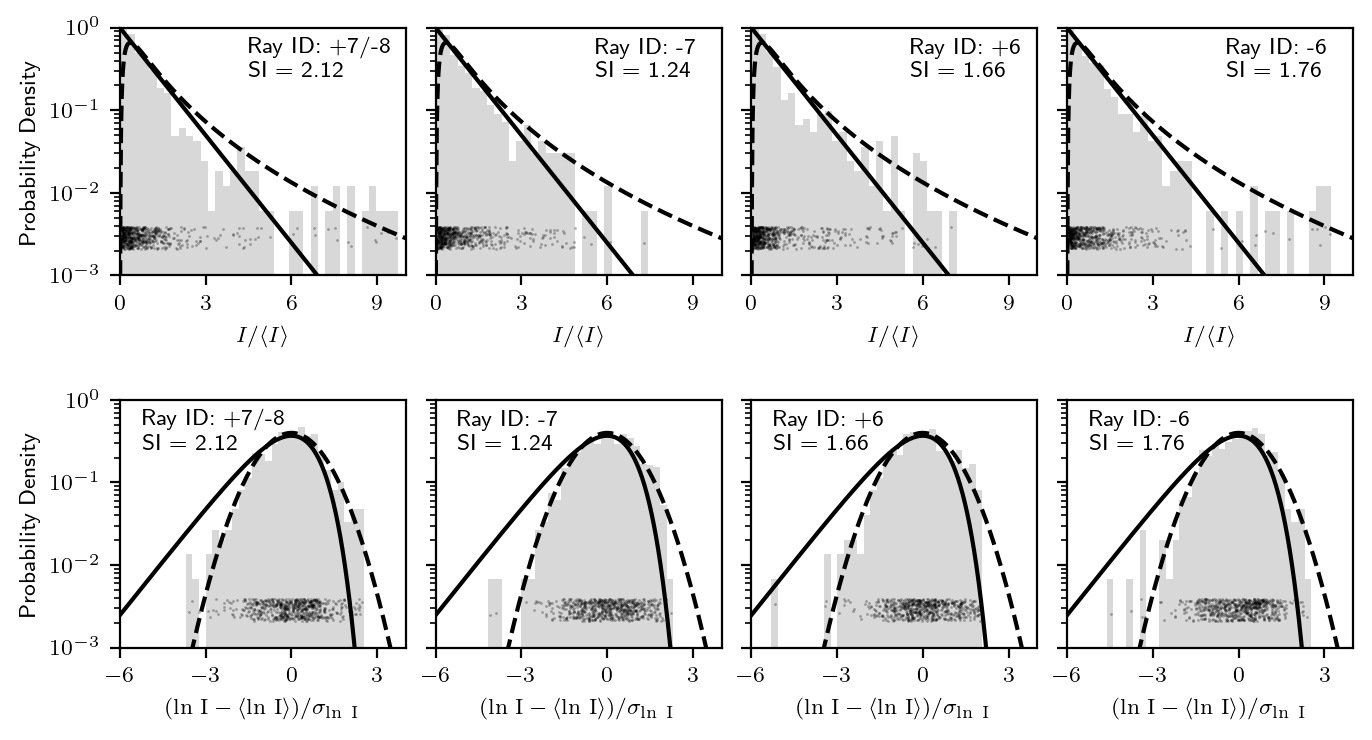

In [11]:
plt.rcParams.update({"font.size": 8})
plt.rcParams.update({"text.usetex": True})

fig, axes = plt.subplots(2, 4, figsize=(6.68, 3.5))
axes = axes.flatten()

for k, ray_id in enumerate(ducted_peaks):
    # Intensity Distribution
    plt.sca(axes[k])

    _ = plt.hist(
        I_norm[ray_id],
        bins=np.linspace(0, 10, 40),
        alpha=0.3,
        density=True,
        color="gray",
    )

    plt.scatter(
        y=3e-3 * np.random.uniform(0.7, 1.3, 644),
        x=I_norm[ray_id].flatten(),
        lw=0,
        alpha=0.3,
        s=1,
        c="k",
    )

    x_plot = np.linspace(0, 10, 1000)
    # exponential distribution
    plt.plot(x_plot, np.exp(-x_plot), c="k")

    # log-normal distribution
    sigma = 1
    lognormal_f = (
        1
        / (x_plot * np.sqrt(2 * np.pi) * sigma)
        * np.exp(-1 * (np.log(x_plot) ** 2) / (2 * (sigma**2)))
    )
    plt.plot(x_plot, lognormal_f, c="k", linestyle="--")

    plt.yscale("log")
    plt.ylim([1e-3, 1e0])
    # plt.title(ray_id, loc='left', fontsize=10, pad=-3)

    if ray_id == "+7":
        plt.text(4.5, 2.5e-1, f"Ray ID: +7/-8\nSI = {SI[ray_id]:0.2f}")
    else:
        plt.text(5.6, 2.5e-1, f"Ray ID: {ray_id}\nSI = {SI[ray_id]:0.2f}")
    plt.xlabel("$ I / \\langle I \\rangle$")
    plt.xlim([0, 10])
    plt.xticks(np.arange(0, 10, 3))

    # Log-Intensity Distribution
    plt.sca(axes[k + 4])
    _ = plt.hist(
        lI_norm[ray_id],
        bins=np.linspace(-6, 3, 40),
        alpha=0.3,
        density=True,
        color="gray",
    )

    plt.scatter(
        y=3e-3 * np.random.uniform(0.7, 1.3, 644),
        x=lI_norm[ray_id].flatten(),
        lw=0,
        alpha=0.3,
        s=1,
        c="k",
    )

    x_plot = np.linspace(-6, 4, 1000)
    plt.plot(x_plot, np.exp(x_plot - np.exp(x_plot)), "-k")
    sigma = 1
    f_norm = 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-0.5 * (x_plot / sigma) ** 2)
    plt.plot(x_plot, f_norm, "--k")

    plt.yscale("log")
    plt.ylim([1e-3, 1e0])
    plt.xlim([-6, 4])
    plt.xticks(np.arange(-6, 4, 3))
    plt.xlabel(
        "$(\\mathrm{ln \\ I} - \\langle \\mathrm{ln \\ I} \\rangle) / \\sigma_{\\mathrm{ln \\ I}}$"
    )
    # plt.title(ray_id, loc='left', fontsize=10, pad=-3)

    if ray_id == "+7":
        plt.text(-5.2, 2.5e-1, f"Ray ID: +7/-8\nSI = {SI[ray_id]:0.2f}")
    else:
        plt.text(-5.2, 2.5e-1, f"Ray ID: {ray_id}\nSI = {SI[ray_id]:0.2f}")

# axes level formatting
for k in range(8):
    if k % 4 == 0:
        axes[k].set_ylabel("Probability Density")
    else:
        axes[k].set_yticklabels("")

plt.tight_layout(pad=0, h_pad=2)

fig.savefig("../../figures/Ducted_Intensity_Distribution.pdf", bbox_inches="tight")

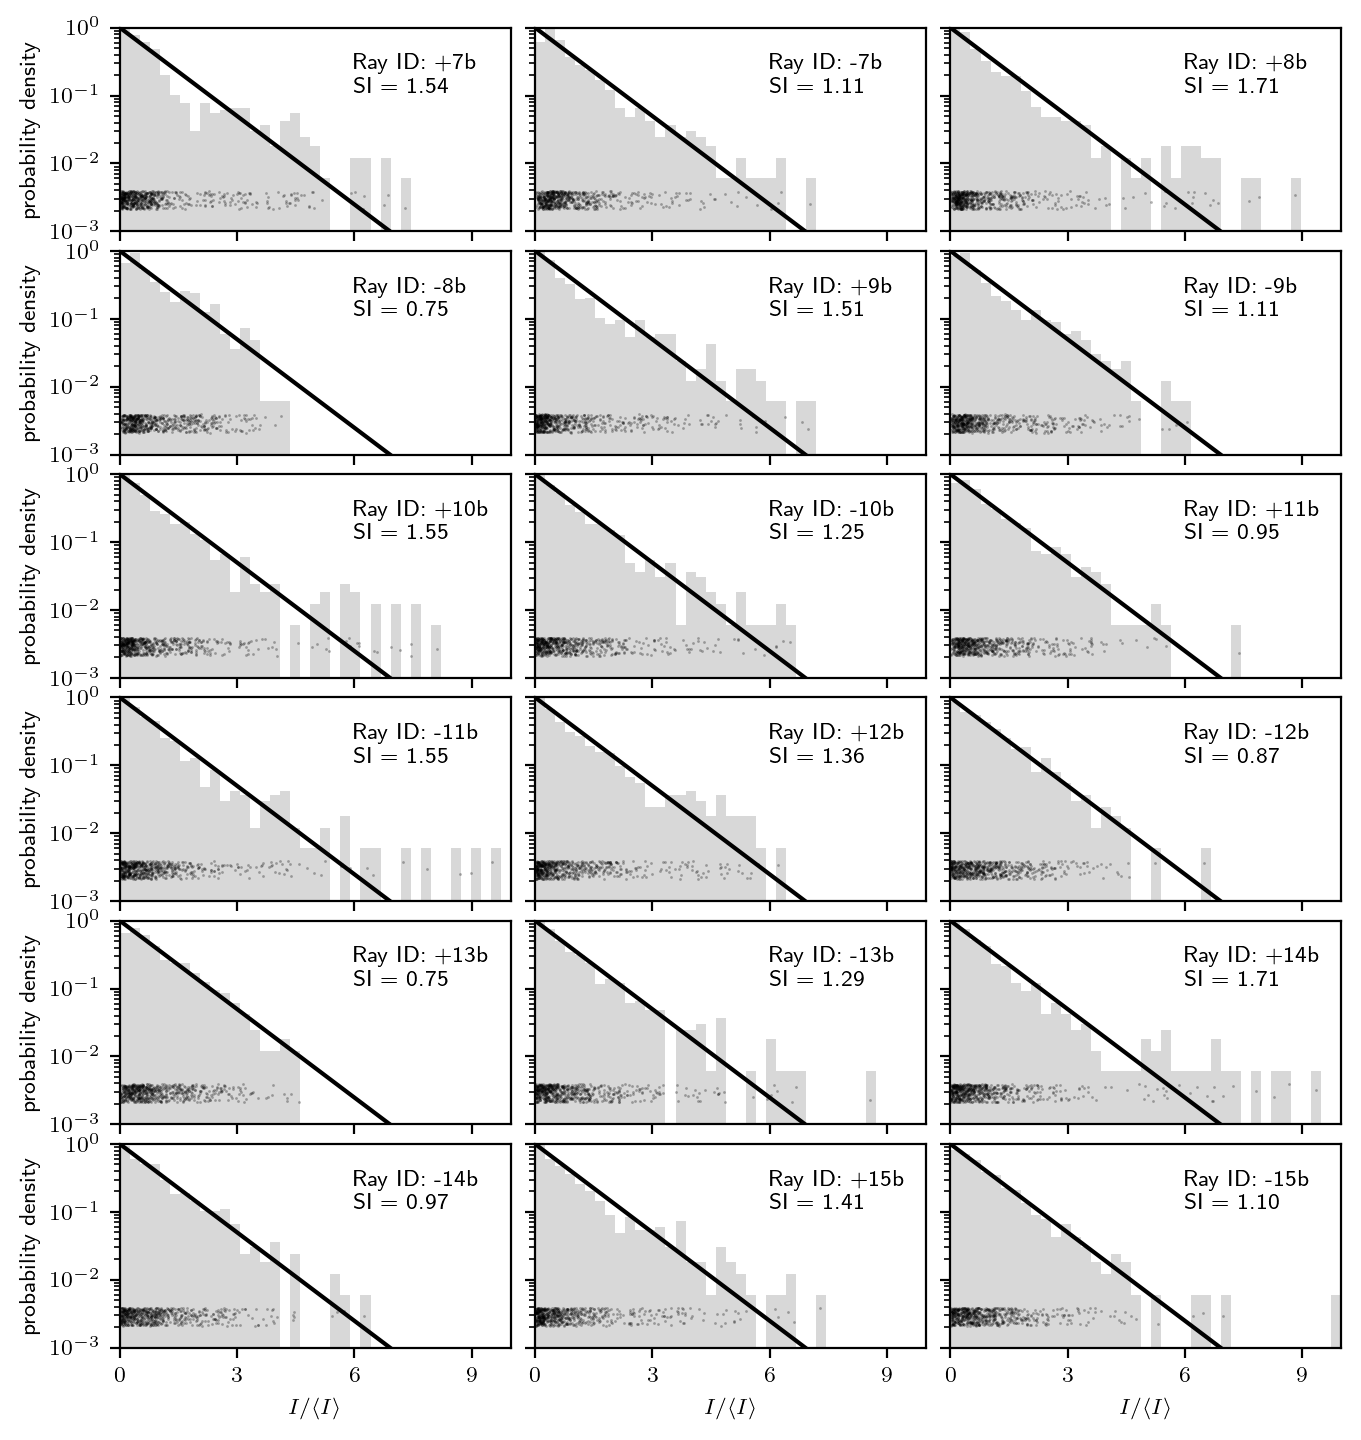

In [12]:
plt.rcParams.update({"font.size": 8})
plt.rcParams.update({"text.usetex": True})

fig, axes = plt.subplots(6, 3, figsize=(6.68, 7))
axes = axes.flatten()

for k, ray_id in enumerate(boundary_peaks):
    # Intensity Distribution
    plt.sca(axes[k])

    _ = plt.hist(
        I_norm[ray_id],
        bins=np.linspace(0, 10, 40),
        alpha=0.3,
        density=True,
        color="gray",
    )

    plt.scatter(
        y=3e-3 * np.random.uniform(0.7, 1.3, 644),
        x=I_norm[ray_id].flatten(),
        lw=0,
        alpha=0.3,
        s=1,
        c="k",
    )

    x_plot = np.linspace(0, 8, 1000)
    plt.plot(x_plot, np.exp(-x_plot), c="k")

    plt.yscale("log")
    plt.ylim([1e-3, 1e0])
    # plt.title(ray_id, loc='left', fontsize=10, pad=-3)

    plt.text(6, 1.1e-1, f"Ray ID: {ray_id}\nSI = {SI[ray_id]:0.2f}")

    plt.xlabel("$ I / \\langle I \\rangle$")
    plt.xlim([0, 10])
    plt.xticks(np.arange(0, 10, 3))

    if k % 3 != 0:
        axes[k].set_yticklabels("")
    else:
        axes[k].set_ylabel("probability density")

    if k >= 15:
        plt.xlabel("$ I / \\langle I \\rangle$")
    else:
        plt.xlabel("")
        axes[k].set_xticklabels("")
    # plt.title(ray_id, loc='left', fontsize=10, pad=-3)

    # plt.text(-5, 3e-1, f'SI = {SI[ray_id]:0.2f}')

plt.tight_layout(pad=0)

fig.savefig(
    "../../figures/Boundary_Intensity_Distribution_linear.pdf", bbox_inches="tight"
)

In [ ]:
plt.rcParams.update({"font.size": 8})
plt.rcParams.update({"text.usetex": True})

fig, axes = plt.subplots(6, 3, figsize=(6.68, 7))
axes = axes.flatten()

for k, ray_id in enumerate(boundary_peaks):
    # Intensity Distribution
    plt.sca(axes[k])

    # Log-Intensity Distribution
    plt.sca(axes[k])
    _ = plt.hist(
        lI_norm[ray_id],
        bins=np.linspace(-6, 3, 40),
        alpha=0.3,
        density=True,
        color="gray",
    )

    plt.scatter(
        y=3e-3 * np.random.uniform(0.7, 1.3, 644),
        x=lI_norm[ray_id].flatten(),
        lw=0,
        alpha=0.3,
        s=1,
        c="k",
    )

    x_plot = np.linspace(-6, 4, 1000)
    plt.plot(x_plot, np.exp(x_plot - np.exp(x_plot)), "-k")

    sigma = 1
    f_norm = 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-0.5 * (x_plot / sigma) ** 2)
    plt.plot(x_plot, f_norm, "--k")

    plt.yscale("log")
    plt.ylim([1e-3, 1e0])
    plt.xlim([-4, 4])
    plt.xticks(np.arange(-6, 4, 3))
    plt.yticks(np.logspace(-2, 0, 3))
    plt.text(-5.5, 2e-1, f"Ray ID: {ray_id}\nSI = {SI[ray_id]:0.2f}")

    if k % 3 != 0:
        axes[k].set_yticklabels("")
    else:
        axes[k].set_ylabel("probability density")

    if k >= 15:
        plt.xlabel(
            "$(\\mathrm{ln \\ I} - \\langle \\mathrm{ln \\ I} \\rangle) / \\sigma_{\\mathrm{ln \\ I}}$"
        )
    else:
        plt.xlabel("")
        axes[k].set_xticklabels("")
    # plt.title(ray_id, loc='left', fontsize=10, pad=-3)

    # plt.text(-5, 3e-1, f'SI = {SI[ray_id]:0.2f}')

plt.tight_layout(pad=0)


fig.savefig(
    "../../figures/Boundary_Intensity_Distribution_log.pdf", bbox_inches="tight"
)